# 🌾 Leaf Disease Detection — Crop Detection Pipeline
### YOLOv8 (5-Crop Detection) + Groq Llama-4-Scout (Zero-Shot Crop Identification)

**Team:** Ashmit Janjirkar, Hitansh Gada, Aryan Gada, Urav Jain
**Guide:** Dr. Monika Mangla — DJSCE, Dept. of Information Technology

**Classes:** `0: sugarcane` · `1: wheat` · `2: maize` · `3: rice` · `4: soybean`

---

This notebook combines two pipelines:
1. **YOLOv8 Object Detection** — trained on the merged 5-crop dataset (bounding-box localisation)
2. **Groq Vision-Language Model** — zero-shot crop identification fallback using `meta-llama/llama-4-scout-17b-16e-instruct`

Runs on free-tier Colab/Kaggle T4 GPU.

---

## 1. Environment Setup

In [ ]:
# Install dependencies
!pip install ultralytics groq pyyaml -q
!pip install roboflow -q   # optional — only needed if downloading dataset directly

import os, yaml, torch
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 71.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.0/285.0 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 142.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.7 MB/s eta 0:00:00
CUDA available: True
Device: Tesla T4


### 1.1 (Optional) Mount Google Drive
Uncomment if your merged dataset lives on Drive rather than local runtime storage.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATASET_ROOT = "/content/drive/MyDrive/dataset"

DATASET_ROOT = "/content/drive/MyDrive/dataset"   # local runtime path — change if using Drive/Kaggle input

Mounted at /content/drive


In [ ]:
import os
print("DATASET_ROOT:", DATASET_ROOT)
print("Exists:", os.path.exists(DATASET_ROOT))
print("Contents:", os.listdir(DATASET_ROOT) if os.path.exists(DATASET_ROOT) else "N/A")

DATASET_ROOT: /content/drive/MyDrive/dataset
Exists: True
Contents: ['images', 'labels', 'crop_dataset.yaml']


## 2. Dataset — Merged 5-Crop YOLO Dataset

Expected structure (already merged via `merge_datasets.py`):

```
dataset/
├── images/
│   ├── train/
│   ├── val/
│   └── test/
├── labels/
│   ├── train/
│   ├── val/
│   └── test/
└── crop_dataset.yaml
```

If you haven't merged your 5 per-crop folders yet, run `merge_datasets.py` locally first,
or download directly from Roboflow below.

In [ ]:
# ── Option A: Download pre-merged dataset from Roboflow (recommended) ──────
# from roboflow import Roboflow
# rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
# project = rf.workspace("s2s3").project("yoyo9")
# dataset = project.version(1).download("yolov8", location=DATASET_ROOT)

# ── Option B: Use already-merged local dataset ──────────────────────────────
assert os.path.exists(DATASET_ROOT), f"Dataset not found at {DATASET_ROOT} — run merge_datasets.py first or use Option A"
print("Dataset found:", DATASET_ROOT)

Dataset found: /content/drive/MyDrive/dataset


In [ ]:
# Write / verify the dataset YAML
DATASET_YAML = os.path.join(DATASET_ROOT, "crop_dataset.yaml")

dataset_config = {
    "path": os.path.abspath(DATASET_ROOT),
    "train": "images/train",
    "val":   "images/val",
    "test":  "images/test",
    "nc": 5,
    "names": {
        0: "sugarcane",
        1: "wheat",
        2: "maize",
        3: "rice",
        4: "soybean",
    }
}

with open(DATASET_YAML, "w") as f:
    yaml.dump(dataset_config, f, default_flow_style=False)

print(f"[✓] Dataset YAML ready → {DATASET_YAML}")
print(yaml.dump(dataset_config))

[✓] Dataset YAML ready → /content/drive/MyDrive/dataset/crop_dataset.yaml
names:
  0: sugarcane
  1: wheat
  2: maize
  3: rice
  4: soybean
nc: 5
path: /content/drive/MyDrive/dataset
test: images/test
train: images/train
val: images/val



In [ ]:
# Quick sanity check — count images per split
for split in ["train", "val", "test"]:
    img_dir = os.path.join(DATASET_ROOT, "images", split)
    if os.path.exists(img_dir):
        n = len([f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        print(f"  {split:6s}: {n} images")
    else:
        print(f"  {split:6s}: NOT FOUND")

  train : 9716 images
  val   : 1130 images
  test  : 551 images


### 2.1 Visualize a few sample images + labels

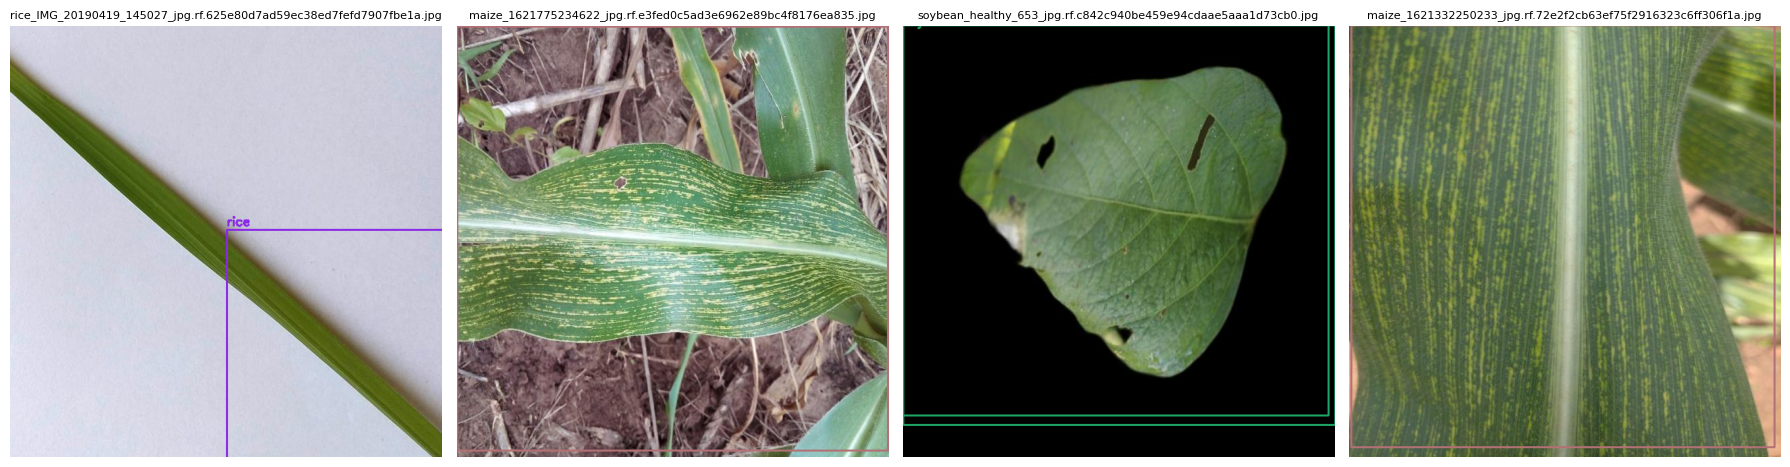

In [ ]:
import matplotlib.pyplot as plt
import cv2, random

CLASS_NAMES = ["sugarcane", "wheat", "maize", "rice", "soybean"]
COLORS = [(27,158,117), (217,95,2), (117,112,179), (231,41,138), (102,166,30)]

def draw_yolo_labels(img_path, lbl_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    h, w = img.shape[:2]
    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f.readlines():
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                cls_id, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:5])
                x1 = int((xc - bw/2) * w); y1 = int((yc - bh/2) * h)
                x2 = int((xc + bw/2) * w); y2 = int((yc + bh/2) * h)
                color = COLORS[cls_id % len(COLORS)]
                cv2.rectangle(img, (x1,y1), (x2,y2), color, 2)
                cv2.putText(img, CLASS_NAMES[cls_id], (x1, max(y1-6,0)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

train_img_dir = os.path.join(DATASET_ROOT, "images", "train")
train_lbl_dir = os.path.join(DATASET_ROOT, "labels", "train")

if os.path.exists(train_img_dir):
    sample_imgs = random.sample(os.listdir(train_img_dir), min(4, len(os.listdir(train_img_dir))))
    fig, axes = plt.subplots(1, len(sample_imgs), figsize=(18, 5))
    if len(sample_imgs) == 1:
        axes = [axes]
    for ax, fname in zip(axes, sample_imgs):
        img_path = os.path.join(train_img_dir, fname)
        lbl_path = os.path.join(train_lbl_dir, os.path.splitext(fname)[0] + ".txt")
        vis = draw_yolo_labels(img_path, lbl_path)
        if vis is not None:
            ax.imshow(vis)
            ax.set_title(fname, fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No training images found to visualize yet.")

## 3. YOLOv8 Training

Trains on the merged 5-class dataset. Uses `yolov8n` by default for fast iteration on free-tier T4 —
switch to `yolov8s`/`yolov8m` for higher accuracy once the pipeline is validated.

In [ ]:
from ultralytics import YOLO

MODEL_SIZE = "n"          # n | s | m | l | x
EPOCHS     = 30
IMG_SIZE   = 640
BATCH      = 32
DEVICE     = 0 if torch.cuda.is_available() else "cpu"

model = YOLO(f"yolov8{MODEL_SIZE}.pt")
print(f"[✓] Loaded pretrained yolov8{MODEL_SIZE}.pt")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[✓] Loaded pretrained yolov8n.pt


In [ ]:
import shutil, os

LOCAL_DATASET = "/content/dataset"

if not os.path.exists(LOCAL_DATASET):
    print("Copying dataset from Drive to local disk — this may take a few minutes...")
    shutil.copytree(DATASET_ROOT, LOCAL_DATASET)
    print("[✓] Copy complete.")
else:
    print("Local dataset already exists, skipping copy.")

# Point everything at the local copy from here on
DATASET_ROOT = LOCAL_DATASET
DATASET_YAML = os.path.join(DATASET_ROOT, "crop_dataset.yaml")

print("Now training will read from:", DATASET_ROOT)

Copying dataset from Drive to local disk — this may take a few minutes...
[✓] Copy complete.
Now training will read from: /content/dataset


In [ ]:
results = model.train(
    data      = DATASET_YAML,
    epochs    = EPOCHS,
    imgsz     = IMG_SIZE,
    batch     = BATCH,
    device    = DEVICE,
    project   = "runs/crop_detect",
    name      = "exp1",

    # Augmentation — tuned for field-condition variability
    hsv_h     = 0.015,
    hsv_s     = 0.7,
    hsv_v     = 0.4,
    flipud    = 0.5,
    fliplr    = 0.5,
    mosaic    = 1.0,
    mixup     = 0.1,
    copy_paste= 0.1,
    degrees   = 10.0,
    translate = 0.1,
    scale     = 0.5,
    shear     = 2.0,
)

BEST_WEIGHTS = "runs/crop_detect/exp1/weights/best.pt"
print(f"\n[✓] Training complete. Best weights → {BEST_WEIGHTS}")

Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/crop_dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp1, nbs=64, nms=False, 

In [ ]:
import os
for root, dirs, files in os.walk("runs"):
    for f in files:
        print(os.path.join(root, f))

runs/detect/runs/crop_detect/exp1/val_batch2_pred.jpg
runs/detect/runs/crop_detect/exp1/labels.jpg
runs/detect/runs/crop_detect/exp1/train_batch2.jpg
runs/detect/runs/crop_detect/exp1/val_batch0_labels.jpg
runs/detect/runs/crop_detect/exp1/train_batch6062.jpg
runs/detect/runs/crop_detect/exp1/train_batch6060.jpg
runs/detect/runs/crop_detect/exp1/train_batch0.jpg
runs/detect/runs/crop_detect/exp1/results.csv
runs/detect/runs/crop_detect/exp1/BoxR_curve.png
runs/detect/runs/crop_detect/exp1/confusion_matrix.png
runs/detect/runs/crop_detect/exp1/results.png
runs/detect/runs/crop_detect/exp1/val_batch1_labels.jpg
runs/detect/runs/crop_detect/exp1/train_batch1.jpg
runs/detect/runs/crop_detect/exp1/BoxPR_curve.png
runs/detect/runs/crop_detect/exp1/val_batch2_labels.jpg
runs/detect/runs/crop_detect/exp1/args.yaml
runs/detect/runs/crop_detect/exp1/BoxF1_curve.png
runs/detect/runs/crop_detect/exp1/BoxP_curve.png
runs/detect/runs/crop_detect/exp1/confusion_matrix_normalized.png
runs/detect/runs/

### 3.1 Training Curves

In [ ]:
from IPython.display import Image, display
results_png = "runs/crop_detect/exp1/results.png"
if os.path.exists(results_png):
    display(Image(filename=results_png, width=900))
else:
    print("results.png not found — check training completed successfully")

results.png not found — check training completed successfully


## 4. Validation — mAP@50, mAP@50-95

In [ ]:
BEST_WEIGHTS = "runs/detect/runs/crop_detect/exp1/weights/best.pt"

best_model = YOLO(BEST_WEIGHTS)
metrics = best_model.val(data=DATASET_YAML, split="val")

print(f"mAP@50    : {metrics.box.map50:.4f}")
print(f"mAP@50-95 : {metrics.box.map:.4f}")
print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")

Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.1±0.9 ms, read: 23.0±23.3 MB/s, size: 33.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/dataset/labels/val.cache... 1098 images, 35 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 1130/1130 263.3Mit/s 0.0s
val: /content/drive/MyDrive/dataset/images/val/rice_IMG_20190419_123551_jpg.rf.38080395714bb40d9e736a1f62f63ff8.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/drive/MyDrive/dataset/images/val/rice_IMG_20190419_123701_jpg.rf.a8aaf6fb1b4deb4a2b7bb5715b62a480.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/drive/MyDrive/dataset/images/val/rice_IMG_20190419_140945_jpg.rf.5

In [ ]:
import shutil, os
DRIVE_BACKUP = "/content/drive/MyDrive/dataset/runs_backup"
os.makedirs(DRIVE_BACKUP, exist_ok=True)
shutil.copytree("runs/detect/runs/crop_detect", os.path.join(DRIVE_BACKUP, "crop_detect"), dirs_exist_ok=True)
print("[✓] Backed up to Drive")

[✓] Backed up to Drive


## 5. Inference — Run YOLOv8 on a Test Image

In [ ]:
TEST_IMAGE = os.path.join(DATASET_ROOT, "images", "test")  # or path to a single image

pred_results = best_model.predict(
    source   = TEST_IMAGE,
    conf     = 0.25,
    save     = True,
    save_txt = True,
    project  = "runs/predict",
    name     = "exp1",
)

for r in pred_results[:5]:
    print(f"\n{r.path}")
    for box in r.boxes:
        cls_id = int(box.cls)
        conf   = float(box.conf)
        print(f"  → {CLASS_NAMES[cls_id]:10s}  conf={conf:.2f}")


image 1/551 /content/dataset/images/test/maize_1621319377241_jpg.rf.26275a2041d885a3f9444c483d7d2149.jpg: 640x640 1 maize, 7.2ms
image 2/551 /content/dataset/images/test/maize_1621320496480_jpg.rf.7b601d22e829d466999adafe3d80356e.jpg: 640x640 1 maize, 7.2ms
image 3/551 /content/dataset/images/test/maize_1621321026799_jpg.rf.55d0fc0e13e4c3fe04bc3565a1220b44.jpg: 640x640 1 maize, 7.2ms
image 4/551 /content/dataset/images/test/maize_1621321757269_jpg.rf.aebbfd9a2076ea7ac1857a2159718780.jpg: 640x640 1 maize, 7.2ms
image 5/551 /content/dataset/images/test/maize_1621324067274_jpg.rf.ab6d4e843a6e8fa36f1e6de1d83f0410.jpg: 640x640 1 maize, 7.2ms
image 6/551 /content/dataset/images/test/maize_1621326285921_jpg.rf.5ffc999e3e14d6db87b9f98c53509854.jpg: 640x640 1 maize, 7.2ms
image 7/551 /content/dataset/images/test/maize_1621329552689_jpg.rf.8c62068ba47b816c6214a12f34d59076.jpg: 640x640 1 maize, 7.3ms
image 8/551 /content/dataset/images/test/maize_1621329661804_jpg.rf.98ab76ae31e3c32bf17e8357e2ba

In [ ]:
# Visualize a predicted sample
pred_dir = "runs/predict/exp1"
if os.path.exists(pred_dir):
    pred_imgs = [f for f in os.listdir(pred_dir) if f.lower().endswith(('.jpg','.png'))]
    if pred_imgs:
        display(Image(filename=os.path.join(pred_dir, pred_imgs[0]), width=600))

## 6. Export to ONNX (for mobile / edge deployment)

In [ ]:
best_model.export(format="onnx", dynamic=True, simplify=True)
onnx_path = BEST_WEIGHTS.replace(".pt", ".onnx")
print(f"[✓] Exported ONNX model → {onnx_path}")

Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from 'runs/detect/runs/crop_detect/exp1/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 9, 8400) (5.9 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 330ms
Prepared 4 packages in 1.83s
Installed 4 packages in 392ms
 + colorama==0.4.6
 + onnx==1.22.0
 + onnxruntime==1.28.0
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 3.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 20...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 9.3s, saved as 'runs/detect/ru

XAI on YOLO — use EigenCAM

In [ ]:
!pip install grad-cam -q

import cv2
import numpy as np
import torch
from pytorch_grad_cam import EigenCAM
from pytorch_grad_cam.utils.image import show_cam_on_image, scale_cam_image

# Inspect the layers to pick a good target (usually the last conv block
# before the Detect head — e.g. the SPPF or last C2f layer)
for i, layer in enumerate(best_model.model.model):
    print(i, layer.__class__.__name__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 117.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
0 Conv
1 Conv
2 C2f
3 Conv
4 C2f
5 Conv
6 C2f
7 Conv
8 C2f
9 SPPF
10 Upsample
11 Concat
12 C2f
13 Upsample
14 Concat
15 C2f
16 Conv
17 Concat
18 C2f
19 Conv
20 Concat
21 C2f
22 Detect


In [ ]:
class YOLOCAMWrapper(torch.nn.Module):
    """Wraps YOLO's DetectionModel so forward() returns a single tensor,
    which is what pytorch-grad-cam's base class expects."""
    def __init__(self, yolo_model):
        super().__init__()
        self.model = yolo_model

    def forward(self, x):
        out = self.model(x)
        if isinstance(out, (tuple, list)):
            return out[0]   # the concatenated predictions tensor
        return out

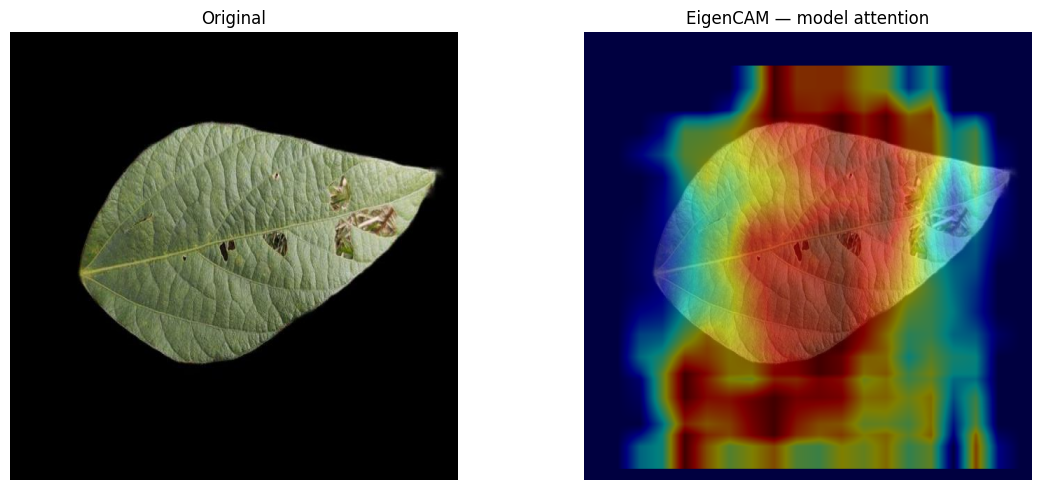

In [ ]:
def yolo_eigencam(model, image_path, target_layer_idx=-2, img_size=640):
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (img_size, img_size))
    rgb_float = img.astype(np.float32) / 255.0

    tensor = torch.from_numpy(rgb_float).permute(2, 0, 1).unsqueeze(0).float()
    device = next(model.model.parameters()).device
    tensor = tensor.to(device)

    # Target layer references the ORIGINAL model — hooks still fire correctly
    # because the wrapper calls this same underlying module internally.
    target_layers = [model.model.model[target_layer_idx]]

    wrapped_model = YOLOCAMWrapper(model.model).to(device).eval()

    cam = EigenCAM(wrapped_model, target_layers)
    grayscale_cam = cam(tensor)[0, :, :]
    grayscale_cam = scale_cam_image(grayscale_cam)

    cam_image = show_cam_on_image(rgb_float, grayscale_cam, use_rgb=True)
    return img, cam_image
orig, heatmap = yolo_eigencam(best_model, sample_image)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(orig); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(heatmap); axes[1].set_title("EigenCAM — model attention"); axes[1].axis("off")
plt.tight_layout()
plt.show()

---
## 7. Vision-Language Model — Zero-Shot Crop Identification (Groq)

Complementary module using **Groq's `llama-4-scout-17b-16e-instruct`** for zero-shot crop
identification directly from an image, without any task-specific training.

Useful as:
- A fallback when the YOLOv8 model isn't yet deployed / covers a new crop
- A quick sanity-check against YOLO predictions
- A lightweight verification layer requiring no GPU

**Free tier:** 30 requests/min, 1,000 requests/day, 30,000 TPM — no credit card required.
Get a key at [console.groq.com](https://console.groq.com).

In [ ]:
import getpass

# Paste your key when prompted (input is hidden) — never hardcode it in the notebook
GROQ_API_KEY = getpass.getpass("Enter your GROQ_API_KEY: ")
os.environ["GROQ_API_KEY"] = GROQ_API_KEY

Enter your GROQ_API_KEY: ··········


In [ ]:
import base64
from groq import Groq

CLASSES = ["sugarcane", "wheat", "maize", "rice", "soybean"]

SYSTEM_PROMPT = f"""You are an expert agricultural pathologist and crop identifier.
Given an image, identify the crop from ONLY these 5 classes: {", ".join(CLASSES)}.
Also assess whether the plant shows visible signs of disease or stress.

Respond in this exact format:
Crop: <crop name>
Confidence: <High / Medium / Low>
Health: <Healthy / Diseased / Uncertain>
Disease: <disease name, or "none" if healthy>
Cure: <brief, practical treatment/management recommendation, or "N/A" if healthy>
Reason: <one line explanation of what visual signs led to this assessment>

If none of the 5 crops are visible, respond with:
Crop: unknown
Confidence: Low
Health: Uncertain
Disease: none
Cure: N/A
Reason: <explanation>

Important: base your disease assessment only on visible symptoms (discoloration,
lesions, spots, wilting, insect damage). Do not guess a specific pathogen with
high confidence if symptoms are ambiguous — say "Uncertain" instead."""

def load_image_base64(image_path: str):
    ext = os.path.splitext(image_path)[-1].lower()
    mime = {".jpg": "image/jpeg", ".jpeg": "image/jpeg",
            ".png": "image/png", ".webp": "image/webp"}.get(ext, "image/jpeg")
    with open(image_path, "rb") as f:
        data = base64.b64encode(f.read()).decode("utf-8")
    return data, mime

def identify_crop(image_path: str) -> dict:
    client = Groq(api_key=os.environ["GROQ_API_KEY"])
    img_data, mime_type = load_image_base64(image_path)

    response = client.chat.completions.create(
        model="qwen/qwen3.6-27b",
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": [
                {"type": "text", "text": "Identify the crop and assess plant health in this image."},
                {"type": "image_url", "image_url": {"url": f"data:{mime_type};base64,{img_data}"}}
            ]}
        ],
        temperature=0.2,
        max_tokens=300,
        reasoning_effort="none",
    )

    raw = response.choices[0].message.content.strip()
    result = {"raw": raw, "crop": "unknown", "confidence": "Low",
              "health": "Uncertain", "disease": "none", "cure": "N/A", "reason": ""}
    for line in raw.splitlines():
        low = line.lower()
        if low.startswith("crop:"):
            result["crop"] = line.split(":", 1)[1].strip().lower()
        elif low.startswith("confidence:"):
            result["confidence"] = line.split(":", 1)[1].strip()
        elif low.startswith("health:"):
            result["health"] = line.split(":", 1)[1].strip()
        elif low.startswith("disease:"):
            result["disease"] = line.split(":", 1)[1].strip()
        elif low.startswith("cure:"):
            result["cure"] = line.split(":", 1)[1].strip()
        elif low.startswith("reason:"):
            result["reason"] = line.split(":", 1)[1].strip()
    return result
print("[✓] Groq crop identifier ready")

[✓] Groq crop identifier ready


── Groq Vision Result ───────────────────
  Image      : /content/dataset/images/test/soybean_healthy_378_jpg.rf.b61eadca6330de9978e63c534f34db22.jpg
  Crop       : SOYBEAN
  Confidence : High
  Reason     : The leaf morphology (ovate shape, pinnate venation) is characteristic of soybean, and the visible holes and chewed edges indicate physical damage from herbivorous insects.
──────────────────────────────────────────


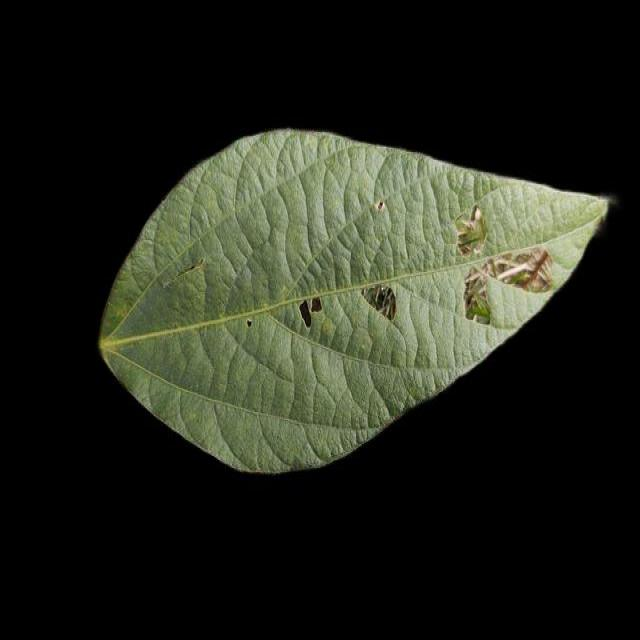

In [ ]:
# Run zero-shot identification on the same test image used for YOLO inference
sample_image = None
test_dir = os.path.join(DATASET_ROOT, "images", "test")
if os.path.exists(test_dir):
    imgs = [f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    if imgs:
        sample_image = os.path.join(test_dir, imgs[0])

if sample_image:
    result = identify_crop(sample_image)
    print("── Groq Vision Result ───────────────────")
    print(f"  Image      : {sample_image}")
    print(f"  Crop       : {result['crop'].upper()}")
    print(f"  Confidence : {result['confidence']}")
    print(f"  Reason     : {result['reason']}")
    print("──────────────────────────────────────────")
    display(Image(filename=sample_image, width=400))
else:
    print("No test image found — set `sample_image` manually to try this.")

### 7.1 Compare YOLOv8 vs Groq VLA on the Same Image
Run both models side by side to cross-verify predictions.

In [ ]:
def compare_predictions(image_path):
    print(f"Image: {image_path}\n")

    # YOLOv8 prediction
    yolo_res = best_model.predict(source=image_path, conf=0.25, save=False, verbose=False)
    print("YOLOv8 detections:")
    if yolo_res and len(yolo_res[0].boxes) > 0:
        for box in yolo_res[0].boxes:
            cls_id = int(box.cls)
            conf   = float(box.conf)
            print(f"  → {CLASS_NAMES[cls_id]:10s}  conf={conf:.2f}")
    else:
        print("  → No detections above threshold")

    # Groq VLA prediction
    groq_res = identify_crop(image_path)
    print(f"\nGroq VLA prediction:")
    print(f"  → {groq_res['crop'].upper():10s}  confidence={groq_res['confidence']}")
    print(f"     reason: {groq_res['reason']}")

if sample_image:
    compare_predictions(sample_image)

Image: /content/dataset/images/test/soybean_healthy_378_jpg.rf.b61eadca6330de9978e63c534f34db22.jpg

Results saved to /content/runs/detect/runs/predict/exp1
526 labels saved to /content/runs/detect/runs/predict/exp1/labels
YOLOv8 detections:
  → soybean     conf=0.83

Groq VLA prediction:
  → SOYBEAN     confidence=High
     reason: The image displays a trifoliate leaf structure with distinct venation and texture characteristic of soybean leaves, showing signs of insect damage.


---
## 8. Summary

| Component | Model | Purpose |
|---|---|---|
| Object Detection | YOLOv8 (`yolov8n`) | Bounding-box localisation of crop/disease regions |
| Zero-Shot Identification | Groq `llama-4-scout-17b-16e-instruct` | Crop verification without training data |
| Export | ONNX (dynamic axes) | Mobile / edge deployment |

**Artifacts produced by this notebook:**
- `runs/crop_detect/exp1/weights/best.pt` — trained YOLOv8 checkpoint
- `runs/crop_detect/exp1/weights/best.onnx` — exported ONNX model
- `runs/predict/exp1/` — annotated inference outputs

**Next steps:** wrap `best.onnx` in the FastAPI backend, integrate both models into the Flutter app,
and add Grad-CAM explainability (see project roadmap).